<b>Program name:</b> GNS1 - Applications of generative models to enhance the performance of complex probabilistic seismic models

<b>Students' names - IDs:</b>

Martin Nguyen - 68623131

Jian Di - 61972461

<b>Descriptions:</b> To reduce the complexity of probabilistic seismic models as well as the amount of computation time and operation work from Open Quake Engine - a well-known Probabilistic Seismic Hazard Analysis (PSHA) model, this three-month project proposed to apply a Generative Adversarial Network (GAN) model - Conditional Tabular Generative Adversarial Network (CTGAN) model. The idea was that the CTGAN model will learn the underlying features from a small sample (about 10-20%) of the entire outputs produced by OpenQuake Engine to generate a similar outcome. The performance would be measured by several different evaluation methods to see how the similarity would be. There would be 3 script reports:

The script report 1 - Main script for the project

The script report 2 - PGA transformation according to the Project Advisor

The script report 3 - Trying the script on the full dataset

-------------------------------------------------------------------

This is the script report 3. The purpose of this report was to show that the script could be run with the full dataset. In this script, the Correlation and Mapping methods were focused. As the results, we could notice that except the event_id was learnt well, the other variables were not learnt well. This might be due to the low number of epochs or due to the outliers which we could see in the EDA part.

The results of this script could be used as the basis for the further studies.

<b>1. DATA HANDLING BEFORE MODELING</b>

<b>1.1. Loading data</b>

In [2]:
# Loading the full dataset
import pandas as pd
HawkesBay_data_full = pd.read_csv("OQ_data_HawkesBay_region.csv")
HawkesBay_data_full

,Unnamed: 0,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
0,0,0,1244.0,0.010817,530.593,0.915348,90.217180,177.362655,-38.809237
1,1,0,1256.0,0.010859,635.389,0.744794,46.398606,177.482655,-38.809237
2,2,0,1261.0,0.010780,1000.000,0.443316,8.266183,177.532655,-38.809237
3,3,0,1466.0,0.010998,1000.000,0.443316,8.266183,177.592655,-38.829237
4,4,0,1561.0,0.013426,1000.000,0.443316,8.266183,177.472655,-38.839237
...,...,...,...,...,...,...,...,...,...
1927169,1927169,996,9186.0,0.011678,1000.000,0.443316,8.266183,176.192655,-39.459237
1927170,1927170,996,9195.0,0.011773,1000.000,0.443316,8.266183,176.282655,-39.459237
1927171,1927171,996,9199.0,0.014754,1000.000,0.443316,8.266183,176.322655,-39.459237
1927172,1927172,996,9200.0,0.012995,1000.000,0.443316,8.266183,176.332655,-39.459237


<b>1.2. Data summary</b>

In [3]:
# Renamed the 'Unnamed: 0' to 'oder'
HawkesBay_data_full = HawkesBay_data_full.rename(columns={'Unnamed: 0': 'order'})

# Checked the dataset
HawkesBay_data_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1927174 entries, 0 to 1927173
Data columns (total 9 columns):
 #   Column    Dtype  
---  ------    -----  
 0   order     int64  
 1   event_id  int64  
 2   site_id   float64
 3   gmv_PGA   float64
 4   Vs30      float64
 5   Z2.5      float64
 6   Z1.0      float64
 7   lon       float64
 8   lat       float64
dtypes: float64(7), int64(2)
memory usage: 132.3 MB


<b>1.2.1. Missing values</b>

In [4]:
# Checking the missing values
num_missing = HawkesBay_data_full.isnull().values.sum()
print('Number of missing values: ', num_missing)

# Checking the data
HawkesBay_data_full[pd.isnull(HawkesBay_data_full["site_id"])]

Number of missing values:  7


,order,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
1927173,1927173,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Removing the missing value
HawkesBay_data_full = HawkesBay_data_full.drop([1927173])

# Checking data
HawkesBay_data_full.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1927173 entries, 0 to 1927172
Data columns (total 9 columns):
 #   Column    Dtype  
---  ------    -----  
 0   order     int64  
 1   event_id  int64  
 2   site_id   float64
 3   gmv_PGA   float64
 4   Vs30      float64
 5   Z2.5      float64
 6   Z1.0      float64
 7   lon       float64
 8   lat       float64
dtypes: float64(7), int64(2)
memory usage: 147.0 MB


<b>1.2.2. Correlation</b>

In [6]:
# Creating function to show the correlation matrix heatmap of a dataframe
# Importing seaborn and matplotlib for using heatmap
import seaborn as sns
import matplotlib.pyplot as plt

# Creating function
def corr_heatmap(df, title):
  '''This function is to show the correlation matrix heatmap of a dataframe.
  For more details please visit: https://datatofish.com/correlation-matrix-pandas/
                                 https://datascience.stackexchange.com/questions/17540/make-seaborn-heatmap-bigger 
  Arguments:
            df:
              Dataframe needs to calculate the correlation matrix
            title:
              Name of the dataframe
  '''
  plt.figure(figsize=(10,10))
  sns.heatmap(df.corr(), annot_kws={"size": 15}, annot=True, cmap="YlGnBu").set_title(f'Correlation matrix of {title}')
  plt.show()

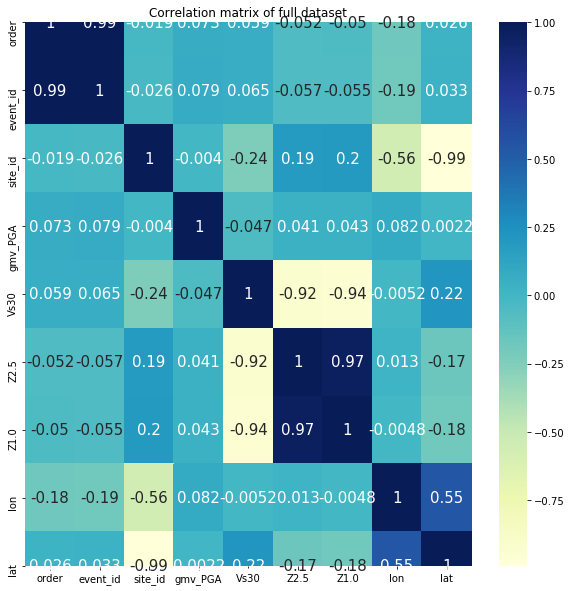

In [7]:
# Checking correlation
corr_heatmap(HawkesBay_data_full, 'full dataset')

<b>1.2.3. Variances</b>

In [8]:
# Checking variance of variables
print('Variance of event_id: ', HawkesBay_data_full.var()['event_id'])
print('Variance of site_id: ', HawkesBay_data_full.var()['site_id'])
print('Variance of PGA: ', HawkesBay_data_full.var()['gmv_PGA'])
print('Variance of Vs30: ', HawkesBay_data_full.var()['Vs30'])
print('Variance of Z2.5: ', HawkesBay_data_full.var()['Z2.5'])
print('Variance of Z1.0: ', HawkesBay_data_full.var()['Z1.0'])
print('Variance of lon: ', HawkesBay_data_full.var()['lon'])
print('Variance of lat: ', HawkesBay_data_full.var()['lat'])

Variance of event_id:  70395.65112241477
Variance of site_id:  21939811.517852027
Variance of PGA:  0.0004955774281478748
Variance of Vs30:  69194.80803635395
Variance of Z2.5:  0.3905959643187546
Variance of Z1.0:  11291.573466290716
Variance of lon:  0.19675849272704124
Variance of lat:  0.21889096481417572


<b>1.2.4. Distributions</b>

Text(0.5, 0.98, 'Distribution of variables in full dataset')

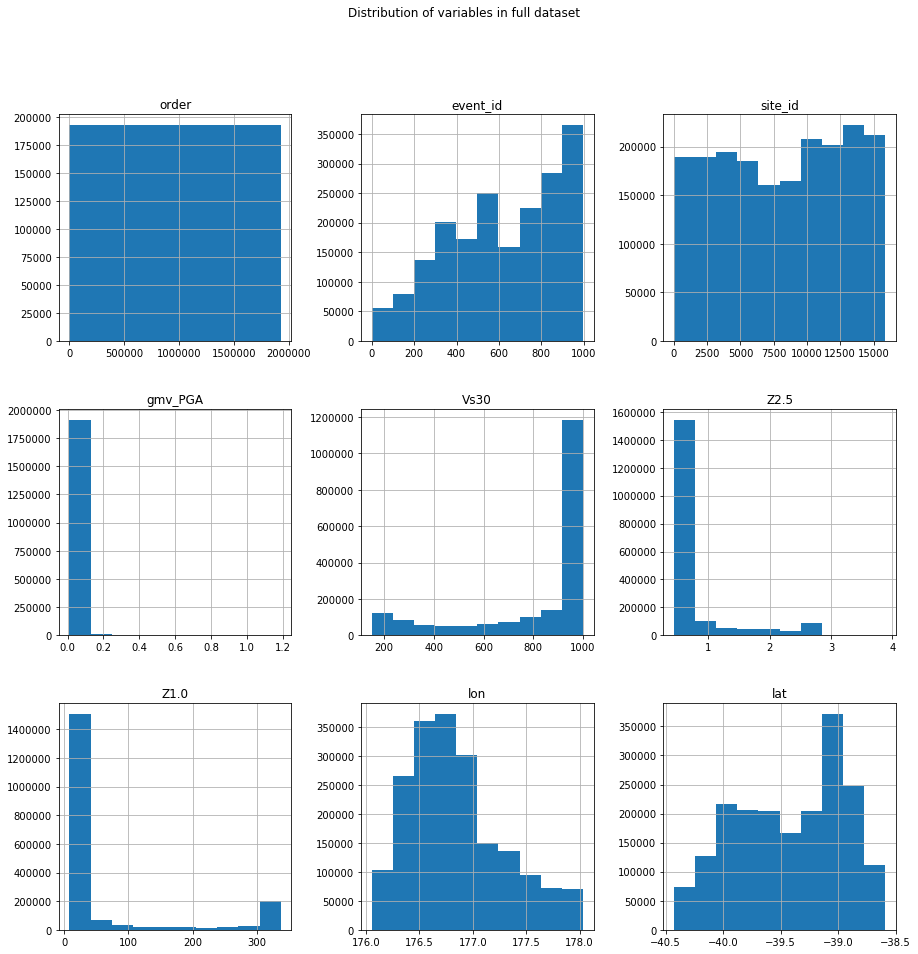

In [9]:
# Checking distributions
HawkesBay_data_full.hist(figsize=(15, 15))
plt.suptitle('Distribution of variables in full dataset')

<b>1.2.5. Other statistical summary</b>

In [10]:
# Checking the general statistical summary
HawkesBay_data_full.drop(columns=['order']).describe()

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
count,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06
mean,6.201857e+02,8.168213e+03,2.530335e-02,8.239278e+02,7.451369e-01,5.977937e+01,1.768460e+02,-3.941956e+01
std,2.653218e+02,4.683995e+03,2.226157e-02,2.630491e+02,6.249768e-01,1.062618e+02,4.435747e-01,4.678578e-01
min,0.000000e+00,0.000000e+00,1.000000e-02,1.500000e+02,4.433162e-01,8.266183e+00,1.760527e+02,-4.042924e+01
25%,4.010000e+02,4.050000e+03,1.299682e-02,7.252880e+02,4.433162e-01,8.266183e+00,1.765127e+02,-3.981924e+01
50%,6.260000e+02,8.394000e+03,1.804735e-02,9.883010e+02,4.493247e-01,8.646085e+00,1.767727e+02,-3.935924e+01
75%,8.510000e+02,1.234400e+04,2.882650e-02,1.000000e+03,6.401615e-01,2.812550e+01,1.770927e+02,-3.901924e+01
max,9.960000e+02,1.587700e+04,1.188596e+00,1.000000e+03,3.883874e+00,3.374264e+02,1.780327e+02,-3.858924e+01


In [11]:
# Creating function to show the boxplots of variables in a dataframe at the same time
# Importing seaborn and matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

# Creating function
def full_boxplots(df, whisker, title):
  '''This function is to show the boxplots of variables in a dataframe at the same time
  For more details please visit: https://seaborn.pydata.org/generated/seaborn.boxplot.html 
  Arguments:
            df:
              Dataframe having variables needs to show the boxplots
            whisker:
              Proportion of the IQR past the low and high quartiles to extend the plot whiskers. 
              Points outside this range will be identified as outliers
            title:
              Name of dataframe
  '''
  plt.figure(figsize=(10,10))
  sns.boxplot(data=df, whis=whisker).set_title(f'Boxplots of {title}')
  plt.show()

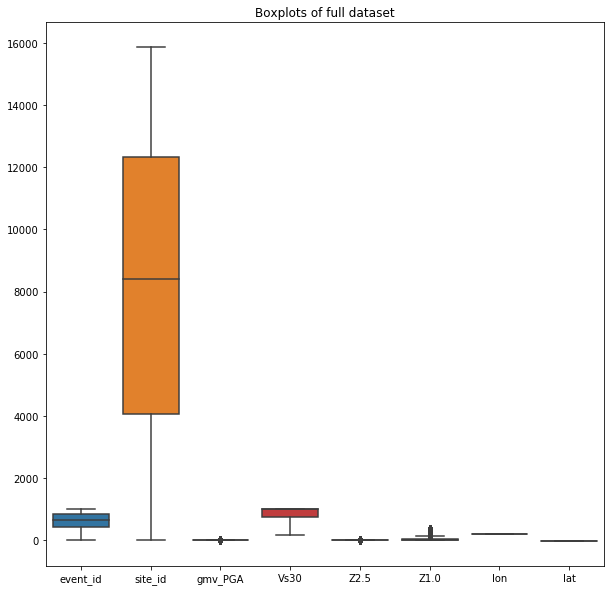

In [12]:
# Checking the boxplots
full_boxplots(HawkesBay_data_full.drop(columns=['order']), 5, 'full dataset')

In [13]:
# Creating function to show the boxplots of each variables in a dataframe
# Importing seaborn and matplotlib
import seaborn as sns
import matplotlib.pyplot as plt

# Creating function
def each_boxplot(df, whisker, lonlat):
  '''This function is to show the boxplots of each variables in a dataframe.
  For more details please visit: https://seaborn.pydata.org/generated/seaborn.boxplot.html 
  Arguments:
            df:
              Dataframe having variables needs to show the boxplots
            whisker:
              Proportion of the IQR past the low and high quartiles to extend the plot whiskers. 
              Points outside this range will be identified as outliers
            lonlat ('y' or 'n'):
              y - yes for showing the boxplots of longitude and latitude
              n - no for showing the boxplots of longitude and latitude
  '''
  if lonlat == 'y':
    # if longitude and latitude needs showing the boxplots
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 15))

    sns.boxplot(data=df[['gmv_PGA']], whis=whisker, ax=axes[0,0]).set_title(f'Boxplot of PGA')
    sns.boxplot(data=df[['Vs30']], whis=whisker, ax=axes[0,1]).set_title(f'Boxplot of Vs30')
    sns.boxplot(data=df[['Z2.5']], whis=whisker, ax=axes[1,0]).set_title(f'Boxplot of Z2.5')
    sns.boxplot(data=df[['Z1.0']], whis=whisker, ax=axes[1,1]).set_title(f'Boxplot of Z1.0')
    sns.boxplot(data=df[['lon']], whis=whisker, ax=axes[2,0]).set_title(f'Boxplot of longitude')
    sns.boxplot(data=df[['lat']], whis=whisker, ax=axes[2,1]).set_title(f'Boxplot of latitude')
  else:
    # if longitude and latitude not need showing the boxplots
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 15))

    sns.boxplot(data=df[['gmv_PGA']], whis=whisker, ax=axes[0,0]).set_title(f'Boxplot of PGA')
    sns.boxplot(data=df[['Vs30']], whis=whisker, ax=axes[0,1]).set_title(f'Boxplot of Vs30')
    sns.boxplot(data=df[['Z2.5']], whis=whisker, ax=axes[1,0]).set_title(f'Boxplot of Z2.5')
    sns.boxplot(data=df[['Z1.0']], whis=whisker, ax=axes[1,1]).set_title(f'Boxplot of Z1.0')

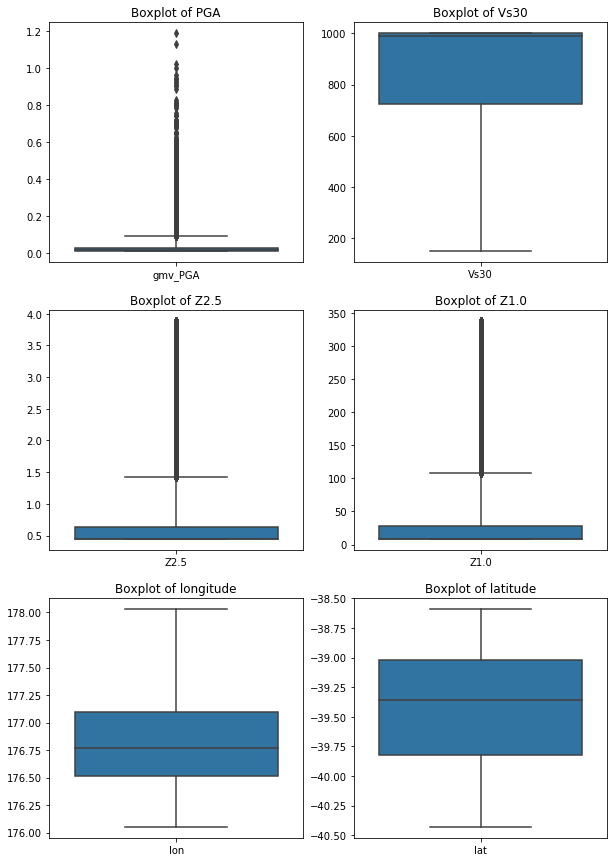

In [14]:
each_boxplot(HawkesBay_data_full, 4, 'y')

<b>1.3. Data handling</b>

In [15]:
# Removing 'order' column                                    
HawkesBay_data = HawkesBay_data_full.drop(columns=["order"])

# Converting site_id format from float to integer
HawkesBay_data.site_id = HawkesBay_data_full.site_id.astype(int)

# Dropping off longitude and latitude for modelling then merging later
HawkesBay_data_droplonlat = HawkesBay_data.drop(columns=['lon', 'lat'])

# Checking data
HawkesBay_data_droplonlat.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1927173 entries, 0 to 1927172
Data columns (total 6 columns):
 #   Column    Dtype  
---  ------    -----  
 0   event_id  int64  
 1   site_id   int64  
 2   gmv_PGA   float64
 3   Vs30      float64
 4   Z2.5      float64
 5   Z1.0      float64
dtypes: float64(4), int64(2)
memory usage: 102.9 MB


<b>2. CTGAN modeling</b>

<b>2.1. Splitting data</b>

In [16]:
# Getting the training sample (20%)
trainingSample = HawkesBay_data_droplonlat.sample(frac=.1)

# Checking data
trainingSample.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 192717 entries, 481460 to 1326768
Data columns (total 6 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   event_id  192717 non-null  int64  
 1   site_id   192717 non-null  int64  
 2   gmv_PGA   192717 non-null  float64
 3   Vs30      192717 non-null  float64
 4   Z2.5      192717 non-null  float64
 5   Z1.0      192717 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 10.3 MB


<b>2.2. Modeling</b>

In [17]:
# Installing the ctgan package version 0.2.2
!pip install ctgan==0.2.2

Defaulting to user installation because normal site-packages is not writeable


In [18]:
# Checking the hyperparameters of CTGANSynthesizer function
from ctgan import CTGANSynthesizer
import inspect
inspect.signature(CTGANSynthesizer)

/data/tmn52/.local/lib/python3.7/site-packages/sklearn/utils/deprecation.py:143: FutureWarning: The sklearn.utils.testing module is  deprecated in version 0.22 and will be removed in version 0.24. The corresponding classes / functions should instead be imported from sklearn.utils. Anything that cannot be imported from sklearn.utils is now part of the private API.
  warnings.warn(message, FutureWarning)


<Signature (embedding_dim=128, gen_dim=(256, 256), dis_dim=(256, 256), l2scale=1e-06, batch_size=500)>

In [19]:
# Building up CTGAN model with epoch=200

ctgan = CTGANSynthesizer(
    embedding_dim=512,
    gen_dim=(512, 256, 64),
    dis_dim=(512, 256, 64),
    l2scale=1e-4, 
    batch_size=3000
)
discrete_columns = ["event_id", 'site_id']
ctgan.fit(trainingSample, discrete_columns,  epochs=10)

/data/tmn52/.local/lib/python3.7/site-packages/torch/cuda/__init__.py:52: UserWarning: CUDA initialization: Found no NVIDIA driver on your system. Please check that you have an NVIDIA GPU and installed a driver from http://www.nvidia.com/Download/index.aspx (Triggered internally at  /pytorch/c10/cuda/CUDAFunctions.cpp:100.)
  return torch._C._cuda_getDeviceCount() > 0
/data/tmn52/.local/lib/python3.7/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_components=10 as keyword args. From version 0.25 passing these as positional arguments will result in an error
  FutureWarning)
/data/tmn52/.local/lib/python3.7/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_components=10 as keyword args. From version 0.25 passing these as positional arguments will result in an error
  FutureWarning)
/data/tmn52/.local/lib/python3.7/site-packages/sklearn/utils/validation.py:70: FutureWarning: Pass n_components=10 as keyword args. From version 0.25 passing these as posi

Epoch 1, Loss G: 4.5244, Loss D: -0.0394
Epoch 2, Loss G: 2.6758, Loss D: -0.0124
Epoch 3, Loss G: 1.4905, Loss D: -0.0135
Epoch 4, Loss G: 0.6342, Loss D: -0.0586
Epoch 5, Loss G: 0.2084, Loss D: -0.0102
Epoch 6, Loss G: 0.3155, Loss D: -0.0081
Epoch 7, Loss G: 0.0699, Loss D: -0.0642
Epoch 8, Loss G: -0.0781, Loss D: -0.0049
Epoch 9, Loss G: 0.0491, Loss D: -0.0220
Epoch 10, Loss G: 0.0344, Loss D: -0.0446


<b>2.3. Saving samples into files</b>

In [20]:
# Checking the current directory
!pwd

/data/tmn52


In [21]:
# Building up the path for saving the files
from pathlib import Path
output_directory = Path('/data/tmn52')

In [22]:
# Installing pyarrow for usage in the below function
!pip install --user pyarrow

In [23]:
## Creating sample of 1927173 observations
# 1927173 - created from looping 14 times of 10000 samples
s = 10000
for v in range(192):
  print(v)
  samples = ctgan.sample(s)
  samples.to_parquet(output_directory / 'CTGAN_output_version47_full_Jian' / f'HawkesBaySyntheticCTGAN{s}samplesVersion{v}.parquet', engine='pyarrow')

# 717 - created separately
sample_rest = ctgan.sample(7173)
sample_rest.to_parquet(output_directory / 'CTGAN_output_version47_full_Jian' / f'HawkesBaySyntheticCTGAN5756samplesVersion15.parquet', engine='pyarrow')

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191


<b>3. Synthetic data</b>

<b>3.1. Gathering data</b>

In [24]:
# Directory of ctgan samples
pathCTGANoutput = output_directory / 'CTGAN_output_version47_full_Jian'

## Creating a function to combine all ctgan samples
import glob # for looking for all the directories having the given path
import os # for joining the paths
import pandas as pd

# Combining all ctgan samples
def read_and_concatenate_parquets(prefix, path=pathCTGANoutput):
  L = []
  files = glob.glob(os.path.join(path, prefix))
  for file in files:
    print("file loaded : {}".format(file))
    pqt = pd.read_parquet(file)
    L.append(pqt)
  df = pd.concat(L)
  return df

In [25]:
# Gathering CTGAN samples
ctgan_df_nolonlat = read_and_concatenate_parquets("HawkesBaySyntheticCTGAN*")

file loaded : /data/tmn52/CTGAN_output_version47_full_Jian/HawkesBaySyntheticCTGAN10000samplesVersion122.parquet
file loaded : /data/tmn52/CTGAN_output_version47_full_Jian/HawkesBaySyntheticCTGAN10000samplesVersion171.parquet
file loaded : /data/tmn52/CTGAN_output_version47_full_Jian/HawkesBaySyntheticCTGAN10000samplesVersion14.parquet
file loaded : /data/tmn52/CTGAN_output_version47_full_Jian/HawkesBaySyntheticCTGAN10000samplesVersion81.parquet
file loaded : /data/tmn52/CTGAN_output_version47_full_Jian/HawkesBaySyntheticCTGAN10000samplesVersion118.parquet
file loaded : /data/tmn52/CTGAN_output_version47_full_Jian/HawkesBaySyntheticCTGAN10000samplesVersion63.parquet
file loaded : /data/tmn52/CTGAN_output_version47_full_Jian/HawkesBaySyntheticCTGAN10000samplesVersion128.parquet
file loaded : /data/tmn52/CTGAN_output_version47_full_Jian/HawkesBaySyntheticCTGAN10000samplesVersion52.parquet
file loaded : /data/tmn52/CTGAN_output_version47_full_Jian/HawkesBaySyntheticCTGAN10000samplesVersio

In [26]:
# Checking general information of ctgan data without longitude and latitude
# since they were not learnt by the ctgan model
ctgan_df_nolonlat.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1927173 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column    Dtype  
---  ------    -----  
 0   event_id  int64  
 1   site_id   int64  
 2   gmv_PGA   float64
 3   Vs30      float64
 4   Z2.5      float64
 5   Z1.0      float64
dtypes: float64(4), int64(2)
memory usage: 102.9 MB


In [27]:
# Merging the synthetic data with longitude and latitude
geometrical_data = pd.read_csv("sitemesh_133.csv")
ctgan_df = pd.merge(ctgan_df_nolonlat, 
                    geometrical_data, 
                    on='site_id', 
                    how='left')

<b>3.2. General statistical summary for synthetic data</b>

<b>3.2.1. Correlation</b>

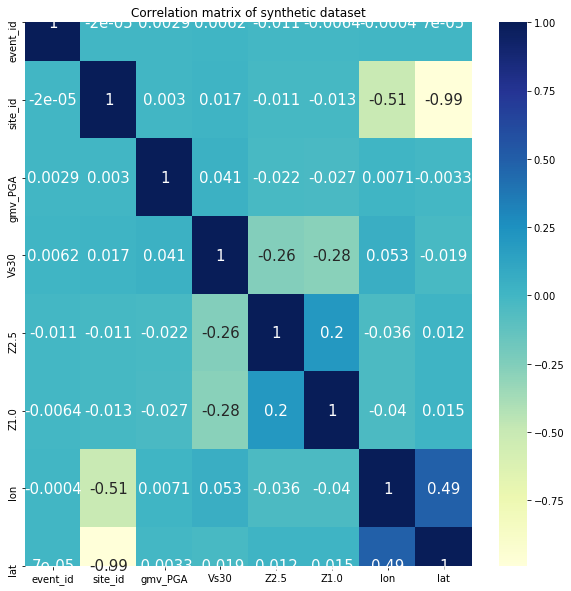

In [28]:
# Checking correlation
corr_heatmap(ctgan_df, 'synthetic dataset')

<b>3.2.2. Variances</b>

In [29]:
# Checking variances
ctgan_df_nolonlat.var()

event_id    7.128601e+04
site_id     2.140587e+07
gmv_PGA     1.990505e-04
Vs30        4.830753e+04
Z2.5        1.665363e-01
Z1.0        8.973585e+03
dtype: float64

<b>3.2.3. Distributions</b>

Text(0.5, 0.98, 'Distribution of variables in synthetic dataset')

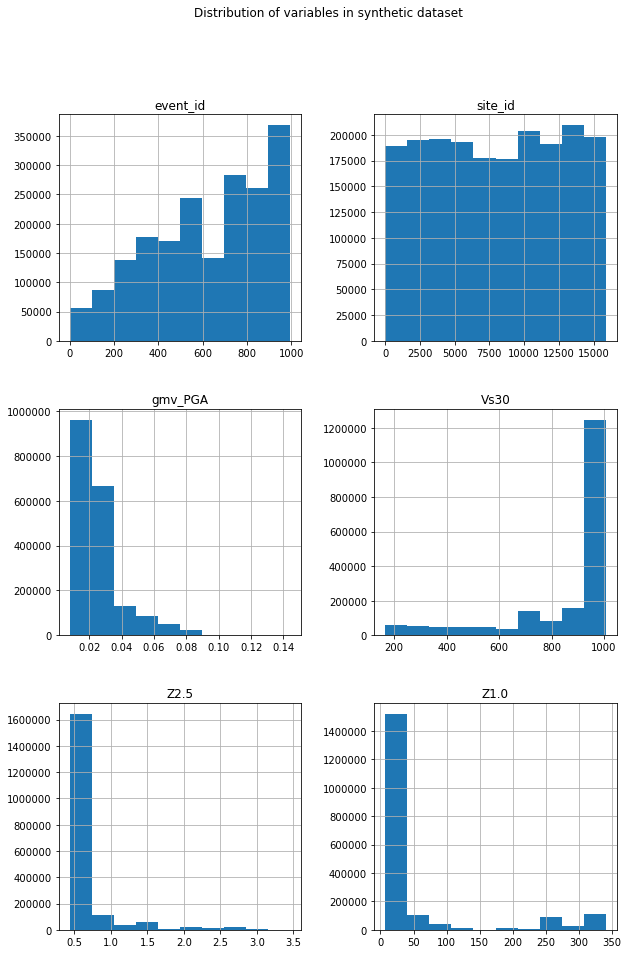

In [30]:
# Checking distributions
ctgan_df_nolonlat.hist(figsize=(10, 15))
plt.suptitle('Distribution of variables in synthetic dataset')

<b>3.2.4. Other statistical summary</b>

In [31]:
# Checking the descriptive summary
ctgan_df_nolonlat.describe()

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0
count,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06,1.927173e+06
mean,6.225991e+02,8.022124e+03,2.630626e-02,8.584851e+02,6.212284e-01,5.206586e+01
std,2.669944e+02,4.626648e+03,1.410853e-02,2.197897e+02,4.080886e-01,9.472901e+01
min,0.000000e+00,0.000000e+00,8.102904e-03,1.658277e+02,4.375255e-01,7.196018e+00
25%,4.030000e+02,3.985000e+03,1.853803e-02,8.261686e+02,4.453602e-01,8.142720e+00
50%,6.470000e+02,8.075000e+03,2.173172e-02,9.824232e+02,4.488685e-01,8.537334e+00
75%,8.500000e+02,1.211300e+04,2.974359e-02,9.996660e+02,5.766759e-01,3.431665e+01
max,9.960000e+02,1.587700e+04,1.442677e-01,1.006380e+03,3.458528e+00,3.406684e+02


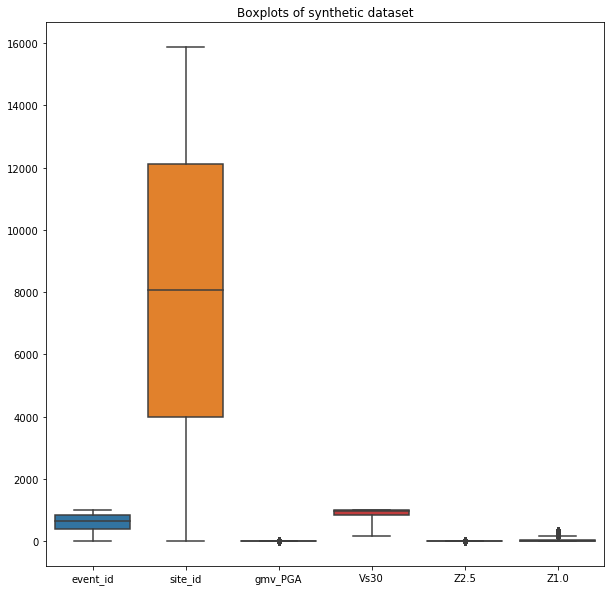

In [32]:
# Checking boxplots
full_boxplots(ctgan_df_nolonlat, 5, 'synthetic dataset')

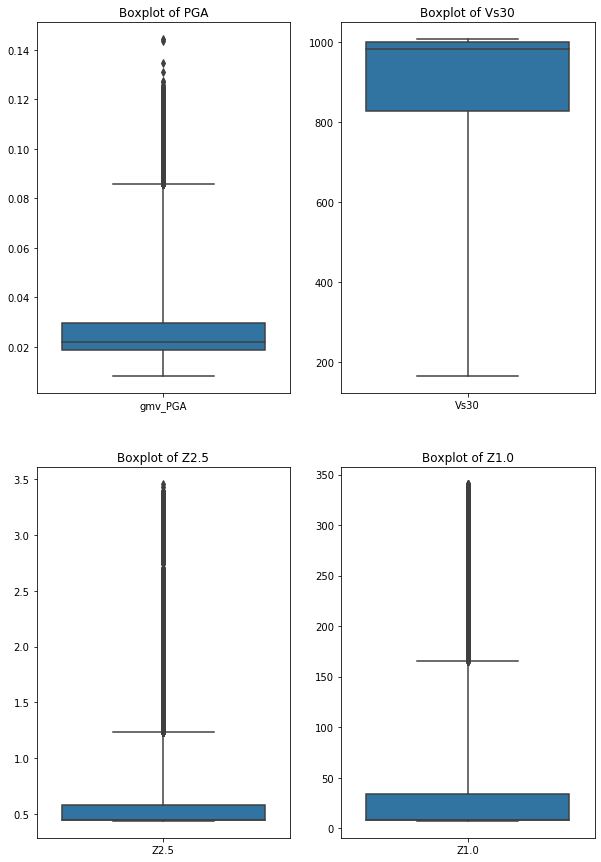

In [33]:
# Checking boxplots of PGA, Vs30, Z2.5, and Z1.0
each_boxplot(ctgan_df_nolonlat, 5, 'n')

<b>4. EVALUATIONS</b>

<b>4.1. Evaluations on all variables by Cosine Similarity method</b>

In [34]:
# Creating copies for both full dataset and synthetic data to evaluate specifically for site_id only
real_copy = HawkesBay_data.copy(deep=True)
ctgan_copy = ctgan_df.copy(deep=True)

In [35]:
# Creating function to do cosine similarity calculation
# This function would be used for site_id and event_id

def calculate_cosine_similarity(column_calculated):
  ''' This function is to calculate cosine similarity of two variables
  Sources: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html#sklearn.metrics.pairwise.cosine_similarity
           https://gist.github.com/pgolding/fdf74a3e8e797fad0391befd5a906ddb
  Arguments:
            column_calculated:
                      The name of the column/variable need calculating cosine similarity.
  '''                    

  # Creating dataframes for both full dataset and synthetic data 
  # Each dataframe contains only one column
  real_dataframe = pd.DataFrame({column_calculated: real_copy[column_calculated]})
  ctgan_dataframe = pd.DataFrame({column_calculated: ctgan_copy[column_calculated]})

  # Converting into numpy array
  real_array = real_dataframe.to_numpy()
  ctgan_array = ctgan_dataframe.to_numpy()

  # Reshaping arrays
  real_array = real_array.reshape(1, -1)
  ctgan_array = ctgan_array.reshape(1, -1)

  # Calculating cosine similarity
  from sklearn.metrics.pairwise import cosine_similarity
  result = cosine_similarity(real_array, ctgan_array)
  return result

In [36]:
ctgan_copy

,event_id,site_id,gmv_PGA,Vs30,Z2.5,Z1.0,lon,lat
0,802,10464,0.075146,718.060582,0.705889,39.854910,176.18266,-39.61924
1,606,14926,0.025043,1000.741687,0.444767,8.275698,176.57265,-40.15924
2,952,8078,0.033931,823.197731,0.485724,20.599218,177.84266,-39.31924
3,380,11921,0.018993,1000.464053,0.446547,7.758861,177.02265,-39.76924
4,559,444,0.027666,724.393174,0.521433,42.347624,177.27265,-38.70924
...,...,...,...,...,...,...,...,...
1927168,985,12729,0.067720,988.385454,2.639370,22.952320,176.98265,-39.85924
1927169,604,13017,0.073177,985.481158,0.446624,8.215108,176.29265,-39.89924
1927170,763,13105,0.064948,999.239032,0.444245,7.990225,176.29265,-39.90924
1927171,787,78,0.014948,933.352925,0.575921,8.148471,177.15266,-38.63924


In [37]:
# Evaluating similarity of variables
# Creating variables containing all columns' names
var_name = real_copy.drop(columns=['lon', 'lat']).columns.to_list()

# Calculating cosine similarity
for name in var_name:
  result = calculate_cosine_similarity(name)[0][0]
  print('Cosine similarity score of {} is: {:.5f}'.format(name, result))

Cosine similarity score of event_id is: 0.84492
Cosine similarity score of site_id is: 0.75134
Cosine similarity score of gmv_PGA is: 0.66123
Cosine similarity score of Vs30 is: 0.92285
Cosine similarity score of Z2.5 is: 0.64052
Cosine similarity score of Z1.0 is: 0.23538


<b>4.2. Evaluations on all variables by Correlation method</b>

In [38]:
# Although matplotlib and seaborn were installed, we still install them again with newer versions
!pip install matplotlib
!pip install seaborn==0.11.1

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [39]:
# Function 1
# Creating a function to calculate Pearson's and Spearman's correlations
# This function would be used for all correlation calculation in this project

%matplotlib inline
plt.style.use('seaborn-whitegrid')
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

def calculate_correlation(real_df, 
                          ctgan_df, 
                          column_merge, 
                          column_correlated,
                          newname_column_correlated):
  ''' The function is used to calculate the correlation similarity - both Pearson and Spearman style
  For more details please visit: https://towardsdatascience.com/calculate-similarity-the-most-relevant-metrics-in-a-nutshell-9a43564f533e
  Arguments:
            real_df:
                Dataframe created from full dataset.
            ctgan_df:
                Dataframe created from synthetic data.
            column_merge:
                Column in both dataframes used to merge.
            column_correlated:
                Current name of columns would be used to calculate correlations.
            newname_column_correlated:
                New name for columns used to calculate correlations.
  '''

  # Preparing data
  dfCorrelation = real_df
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_real_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = pd.merge(dfCorrelation, ctgan_df, how='outer', on=column_merge)
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_ctgan_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = dfCorrelation.fillna(0)

  # Calculating Pearson's correlation
  corrp, _ = stats.pearsonr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                            dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)

  # Calculating Spearman's correlation
  corrs, _ = stats.spearmanr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                             dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)

  return corrp, corrs

In [40]:
# Function 2
# Creating a function to plot the correlations of both styles - Pearson and Spearman
# This function would be used for all correlation calculation in this project

%matplotlib inline
plt.style.use('seaborn-whitegrid')
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

def plot_correlation(real_df, 
                     ctgan_df, 
                     column_merge,
                     column_correlated,
                     newname_column_correlated):
  ''' The function is used to plot the correlation similarity - both Pearson and Spearman styles
  For more details please visit: https://towardsdatascience.com/calculate-similarity-the-most-relevant-metrics-in-a-nutshell-9a43564f533e
  Arguments:
            real_df:
                Dataframe created from dataset.
            ctgan_df:
                Dataframe created from synthetic data.
            column_merge:
                Column in both dataframes used to merge.
            column_correlated:
                Current name of columns would be used to calculate correlations.
            newname_column_correlated:
                New name for columns used to calculate correlations.
  '''

  # Preparing data
  dfCorrelation = real_df
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_real_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = pd.merge(dfCorrelation, ctgan_df, how='outer', on=column_merge)
  dfCorrelation.rename(columns={column_correlated:f'HawkesBay_ctgan_{newname_column_correlated}'}, inplace=True)
  dfCorrelation = dfCorrelation.fillna(0)

  # Calculating Pearson's correlation
  corrp, _ = stats.pearsonr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                            dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)
  print("Pearson's correlation: %.3f" % corrp)

  # Calculating Spearman's correlation
  corrs, _ = stats.spearmanr(dfCorrelation[f'HawkesBay_real_{newname_column_correlated}'].values, 
                             dfCorrelation[f'HawkesBay_ctgan_{newname_column_correlated}'].values)
  print("Spearman's correlation: %.3f" % corrs)

  # Plotting
  plt.style.use('seaborn-whitegrid')
  fig, ax = plt.subplots(figsize=(10, 10))
  pl = sns.regplot(x=f'HawkesBay_ctgan_{newname_column_correlated}', 
                   y=f'HawkesBay_real_{newname_column_correlated}', 
                   data=dfCorrelation, fit_reg=True, 
                   color='black', marker='+', ax=ax)
  pl.set_title(f"Correlation of {newname_column_correlated}")
  plt.show()

<b>4.2.1. Evaluations on frequencies of discrete variables by Correlation method</b>

In [41]:
# Creating a list of discrete variables
discrete_var = var_name[:2][::-1]

# Creating a list of continuous variables
continuous_var = var_name[2:]

In [42]:
# Creating a function to count the frequency of each unique site_id/event_id
def count_fid_occurences(df, column):
  '''The function is used to count the frequency of a given column from a dataframe
  Arguments:
            df:
              Dataframe contains the column.
            column:
              The column needs counting.
  '''
  count = df[column].value_counts()
  count_df = pd.DataFrame({column: count.index, 'count': count.values})
  count_df["count"] = pd.to_numeric(count_df["count"])
  return count_df

In [43]:
# Checking the number of rows by site_id after counting the frequency
# To see if the ctgan model could learn the quantity of unique site_id.
# If the result equals to 0, the model learnt well
len(count_fid_occurences(real_copy, 'site_id')) - len(count_fid_occurences(ctgan_copy, 'site_id'))

2

In [44]:
# Checking the number of rows by event_id after counting the frequency
# To see if the ctgan model could learn the quantity of unique event_id.
# If the result equals to 0, the model learnt well
len(count_fid_occurences(real_copy, 'event_id')) - len(count_fid_occurences(ctgan_copy, 'event_id'))

61

In [45]:
# Creating a function to create a table of correlations for variables
# This function would be used for all correlations in this project 

def corr_df(list_variable_name, type_var):
  ''' This function is to create a dataframe showing Pearson's and Spearman's correlations
      for all variables
  For more details please visit: https://datatofish.com/create-pandas-dataframe/
  Arguments:
            list_variable_name:
                List of names of selected variables in a datasets
            type_var:
                Type of variables - discrete or continuous (d or c)
  '''
  # Creating two lists containing correlations scores for variables
  p_result = []
  s_result = []

  # Calculating correlations for discrete variables
  if type_var == 'd':
    for var in list_variable_name:
      corr_p, corr_s = calculate_correlation(count_fid_occurences(real_copy, var),
                                             count_fid_occurences(ctgan_copy, var),
                                             var, 'count', 'correlation')
      p_result.append(corr_p)
      s_result.append(corr_s)
  # Calculating correlations for continuous variables
  else:
    for var in list_variable_name:
      corr_p, corr_s = calculate_correlation(continuous_var_df(real_mean, var),   # This function would be created later
                                             continuous_var_df(ctgan_mean, var),  # This function would be created later
                                             'site_id', var, 'averaged_'+var)
      p_result.append(corr_p)
      s_result.append(corr_s)

  # Creating a table of correlations for variables
  corr_dict = {'Variables': list_variable_name,
               "Pearson's Correlation": p_result,
               "Spearman's Correlation": s_result}

  corr_df = pd.DataFrame(corr_dict,
                         columns=['Variables', 
                                  "Pearson's Correlation",
                                  "Spearman's Correlation"])

  return corr_df

In [46]:
# Creating a table of correlations of discrete variables
corr_df(discrete_var, 'd')

,Variables,Pearson's Correlation,Spearman's Correlation
0,site_id,0.174601,0.324694
1,event_id,0.820465,0.889159


In [47]:
# Creating a function to call out plots of correlations of variables
# This function would be used for all of correlation plotting in this project

def corr_plot(list_variable_name, type_var):
  ''' This function is to create a dataframe showing Pearson's and Spearman's correlations
      for all variables
  Arguments:
            list_variable_name:
                List of names of selected variables in a datasets
            type_var:
                Type of variables - discrete or continuous (d or c)
  '''
  # Plotting for discrete variables
  if type_var == 'd':
    for var in list_variable_name:
      print()
      print("-"*35 + " " + var + " " + "-"*35)
      plot_correlation(count_fid_occurences(real_copy, var),
                       count_fid_occurences(ctgan_copy, var),
                       var, 'count', var+'_count')
  # Plotting for continuous variables
  else:
    for var in list_variable_name:
      print()
      print("-"*35 + " " + var + " " + "-"*35)
      plot_correlation(continuous_var_df(real_mean, var),   # This function would be created later
                       continuous_var_df(ctgan_mean, var),  # This function would be created later
                       'site_id', var, 'averaged_'+var)
    


----------------------------------- site_id -----------------------------------
Pearson's correlation: 0.175
Spearman's correlation: 0.325


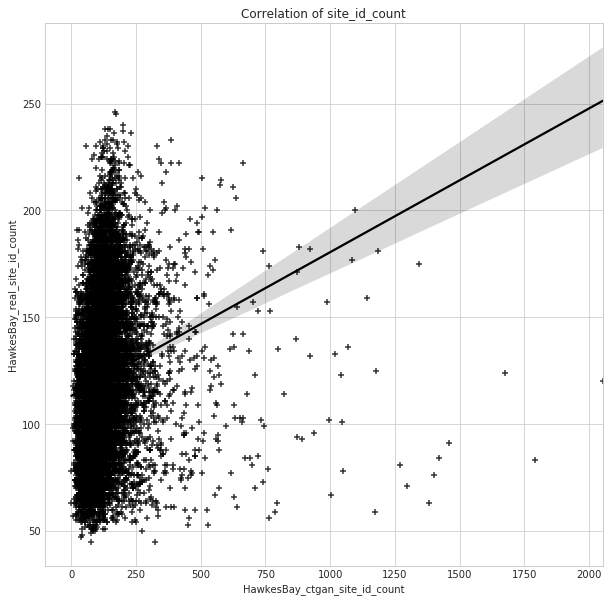


----------------------------------- event_id -----------------------------------
Pearson's correlation: 0.820
Spearman's correlation: 0.889


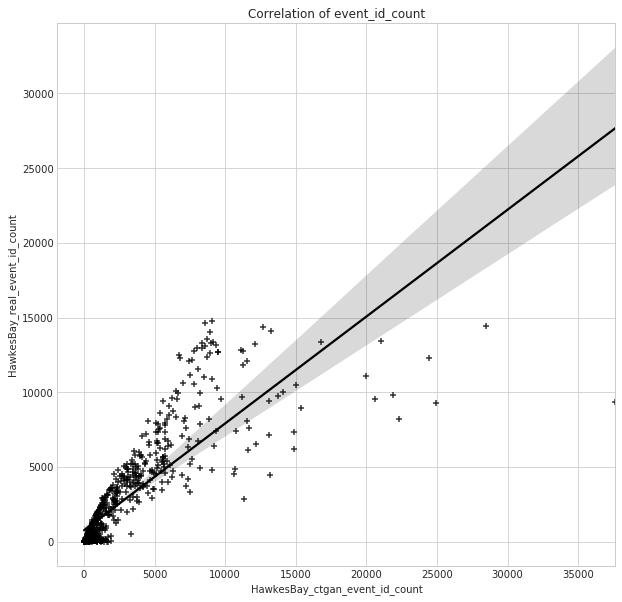

In [48]:
# Plotting correlations for discrete variables
corr_plot(discrete_var, 'd')

<b>4.2.2. Evaluations on values of continuous variables by Correlation method</b>

In [49]:
# Creating a function to create an averaged dataset
def averaged_dataset(df):
  ''' This function is to average dataframe containing longitude and latitude, 
      specifically real data and ctgan data in this project
  Arguments:
            df:
              Dataframe needs averaging
  '''
  # Averaging dataset without longitude and latitude
  df_mean = df.drop(columns=['lon', 'lat']).groupby('site_id').mean()

  # Merging with sitemesh_133.csv file to get longitude and latitude
  df_mean_lonlat = pd.merge(df_mean, geometrical_data, on='site_id')

  return df_mean_lonlat

In [50]:
# Applying averaging function to both real and ctgan dataframes
real_mean = averaged_dataset(real_copy)
ctgan_mean = averaged_dataset(ctgan_copy)

In [51]:
# Checking data information
real_mean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15878 entries, 0 to 15877
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   site_id   15878 non-null  int64  
 1   event_id  15878 non-null  float64
 2   gmv_PGA   15878 non-null  float64
 3   Vs30      15878 non-null  float64
 4   Z2.5      15878 non-null  float64
 5   Z1.0      15878 non-null  float64
 6   lon       15878 non-null  float64
 7   lat       15878 non-null  float64
dtypes: float64(7), int64(1)
memory usage: 1.1 MB


In [52]:
# Checking data information
ctgan_mean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15876 entries, 0 to 15875
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   site_id   15876 non-null  int64  
 1   event_id  15876 non-null  float64
 2   gmv_PGA   15876 non-null  float64
 3   Vs30      15876 non-null  float64
 4   Z2.5      15876 non-null  float64
 5   Z1.0      15876 non-null  float64
 6   lon       15876 non-null  float64
 7   lat       15876 non-null  float64
dtypes: float64(7), int64(1)
memory usage: 1.1 MB


In [53]:
# Creating a function to create a small dataframe including a continuous variable and site_id
def continuous_var_df(df, column):
  '''This function is to create a small dataframe including two columns - 
     site_id and a continuous variable
  Arguments:
            df:
              Dataframe contains the site_id and the continuous variable
            column:
              Column's name
  '''
  con_var_df = pd.DataFrame({'site_id': df.site_id,
                             column: df[column]})
  return con_var_df


----------------------------------- gmv_PGA -----------------------------------
Pearson's correlation: 0.045
Spearman's correlation: 0.051


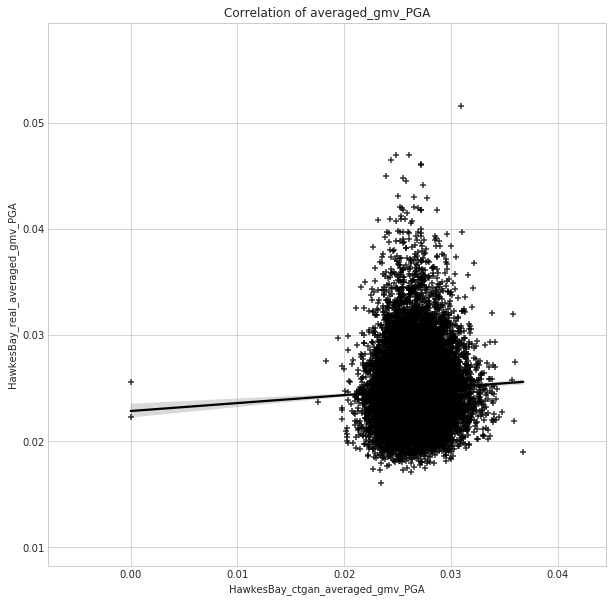


----------------------------------- Vs30 -----------------------------------
Pearson's correlation: -0.173
Spearman's correlation: -0.168


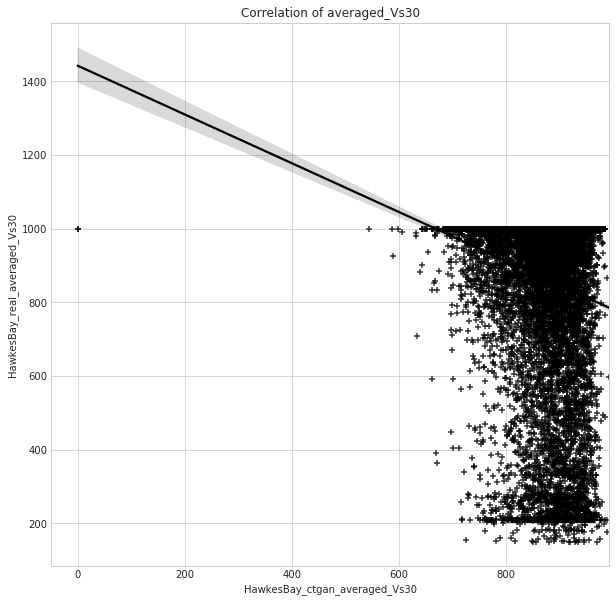


----------------------------------- Z2.5 -----------------------------------
Pearson's correlation: -0.139
Spearman's correlation: -0.083


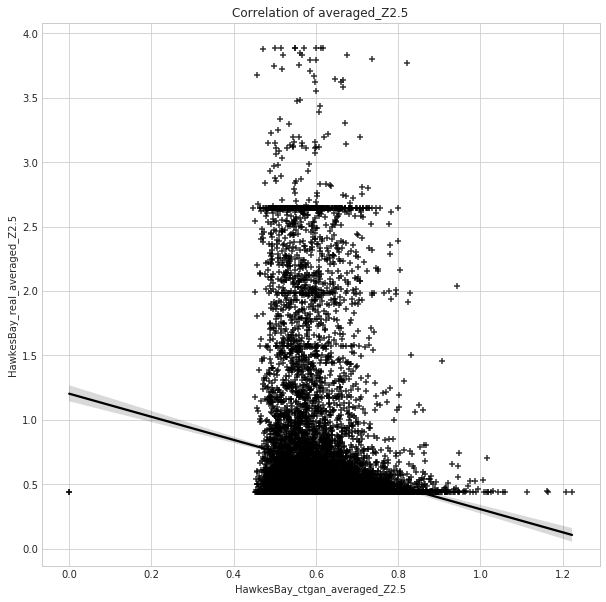


----------------------------------- Z1.0 -----------------------------------
Pearson's correlation: -0.151
Spearman's correlation: -0.171


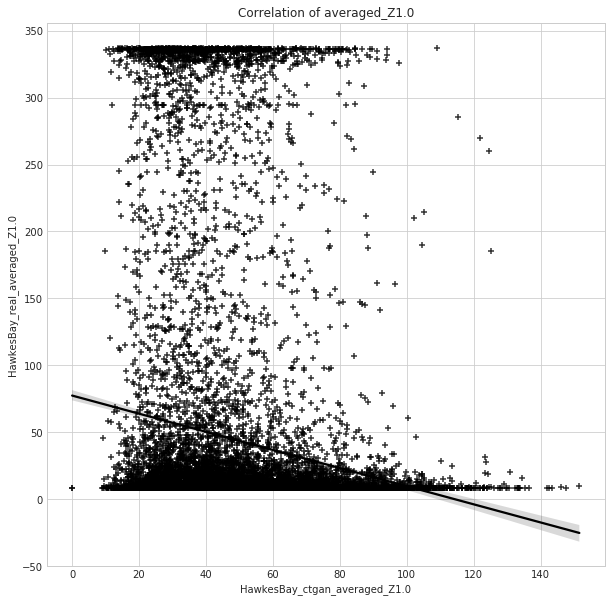

In [54]:
# Plotting correlations for continuous data
corr_plot(continuous_var, 'c')

In [55]:
# Creating a table of correlations of continuous variables
corr_df(continuous_var, 'c')

,Variables,Pearson's Correlation,Spearman's Correlation
0,gmv_PGA,0.044864,0.051138
1,Vs30,-0.172997,-0.168036
2,Z2.5,-0.138978,-0.083244
3,Z1.0,-0.151406,-0.171003


<b>4.3. Evaluations on patterns of continuous variables by Mapping method</b>

In [56]:
# Installing geopandas
!pip install geopandas

Defaulting to user installation because normal site-packages is not writeable


In [57]:
# Creating a function to convert the pandas dataframes 
# into geopandas dataframe for mapping. This function also does
# MinMax and Quantile scaling for a specific variable

# Importing preprocessing from scikit-learn for using scaling functions
from sklearn import preprocessing

# Importing geopandas
import geopandas as gpd

def gdf_minmax_quantile(variable):
  '''This function is to convert the pandas dataframes into geopandas dataframes for mapping.
     It also includes doing scaling with MinMax and Quantile styles for a specific variable.
  For more details please visit: https://geopandas.org/gallery/create_geopandas_from_pandas.html
                                 https://stackoverflow.com/questions/63644131/how-to-use-geopandas-to-plot-latitude-and-longitude-on-a-more-detailed-map-with
  Arguments:
            variable:
                The variable needs mapping
  '''
  # Creating two more copies from the real and ctgan dataframes
  # to avoid the impacts from the further process
  real_mean_copy = real_mean.copy(deep=True)
  ctgan_mean_copy = ctgan_mean.copy(deep=True)

  # Converting pandas dataframes into geopandas dataframes
  gdf_real = gpd.GeoDataFrame(real_mean_copy,
                              geometry = gpd.points_from_xy(real_mean_copy.lon, 
                                                           real_mean_copy.lat))
  gdf_ctgan = gpd.GeoDataFrame(ctgan_mean_copy,
                               geometry = gpd.points_from_xy(ctgan_mean_copy.lon, 
                                                           ctgan_mean_copy.lat))
  
  # Scaling data
  # Calling out scaling functions
  min_max_scaler = preprocessing.MinMaxScaler()
  quantile_scaler = preprocessing.QuantileTransformer()

  # MinMax scaling
  gdf_real['MinMax'] = min_max_scaler.fit_transform(gdf_real[[variable]].values.astype(float))
  gdf_ctgan['MinMax'] = min_max_scaler.fit_transform(gdf_ctgan[[variable]].values.astype(float))
  
  # Quantile scaling
  gdf_real['Quantile'] = quantile_scaler.fit_transform(gdf_real[[variable]].values.astype(float))
  gdf_ctgan['Quantile'] = quantile_scaler.fit_transform(gdf_ctgan[[variable]].values.astype(float))

  return gdf_real, gdf_ctgan

In [58]:
# Creating a function to plot the distributions of the pair - real and ctgan data 
# for averaged, MinMax scaling, Quantile scaling versions

def dis_plot(variable):
  '''This function is to plot the real data and ctgan data distributions
     when averaging, MinMax scaling, and Quantile scaling
  For more details please visit: https://dev.to/thalesbruno/subplotting-with-matplotlib-and-seaborn-5ei8
  Arguments:
          variable:
              The variable needs mapping
  '''
  fig, axes = plt.subplots(2, 3, figsize=(20, 15))
  fig.suptitle(f'Distributions of {variable} of real and ctgan data when averaging, MinMax scaling, and Quantile scaling')

  # Converting pandas dataframes into geopandas dataframes
  # and scaling
  gdf_real_var, gdf_ctgan_var = gdf_minmax_quantile(variable)

  # Real data - Distributions when averaging, MinMax scaling, and Quantile scaling
  sns.distplot(gdf_real_var[variable], kde=True, ax=axes[0, 0]).set_title('Real data distributions - Average')
  sns.distplot(gdf_real_var.MinMax, kde=True, ax=axes[0, 1]).set_title('Real data distributions - MinMax Scaling')
  sns.distplot(gdf_real_var.Quantile, kde=True, ax=axes[0, 2]).set_title('Real data distributions - Quantile Scaling')

  # Ctgan data - Distributions when averaging, MinMax scaling, and Quantile scaling
  sns.distplot(gdf_ctgan_var[variable], kde=True, color='y', ax=axes[1, 0]).set_title('Ctgan data distributions - Average')
  sns.distplot(gdf_ctgan_var.MinMax, kde=True, color='y', ax=axes[1, 1]).set_title('Ctgan distributions - MinMax Scaling')
  sns.distplot(gdf_ctgan_var.Quantile, kde=True, color='y', ax=axes[1, 2]).set_title('Ctgan data distributions - Quantile Scaling')

In [59]:
# Creating a function to map the underlying features of continuous data based on the site_id

# Importing wrap function
from textwrap import wrap

def mapping(variable):
  '''This function is to map the patterns in the real data and ctgan data
     when averaging, MinMax scaling, and Quantile scaling
  For more details please visit: https://dev.to/thalesbruno/subplotting-with-matplotlib-and-seaborn-5ei8
  Arguments:
          variable:
              The variable needs mapping
  '''
  plt.style.use('seaborn-darkgrid')
  fig, ((ax1, ax2), (ax1b, ax2b), (ax1c, ax2c)) = plt.subplots(nrows=3, ncols=2, 
                                                               figsize=(15, 15))
  # Converting pandas dataframes into geopandas dataframes
  # and scaling
  gdf_real_var, gdf_ctgan_var = gdf_minmax_quantile(variable)

  # Averaging
  gdf_real_var.plot(ax=ax1, column=variable, cmap='YlOrRd', legend=True)
  gdf_ctgan_var.plot(ax=ax2, column=variable, cmap='YlOrRd', legend=True)
  ax1.set_title("\n".join(wrap('Averaged - Shaking events in Hawkes Bay - Real data ~ 1 millions observations', 35)))
  ax1.ticklabel_format(useOffset=False, style='plain')
  ax2.set_title("\n".join(wrap('Averaged - Shaking events in Hawkes Bay - CTGAN data ~ 20% observations training set', 35)))
  ax2.ticklabel_format(useOffset=False, style='plain')

  # MinMax scaling 
  gdf_real_var.plot(ax=ax1b, column='MinMax', cmap='YlOrRd', legend=True)
  gdf_ctgan_var.plot(ax=ax2b, column='MinMax', cmap='YlOrRd', legend=True)
  ax1b.set_title("\n".join(wrap('MinMax Scaling - Shaking events in Hawkes Bay - Real data ~ 1 millions observations', 35)))
  ax1b.ticklabel_format(useOffset=False, style='plain')
  ax2b.set_title("\n".join(wrap('MinMax Scaling - Shaking events in Hawkes Bay - CTGAN data ~ CTGAN data ~ 20% observations training set', 35)))
  ax2b.ticklabel_format(useOffset=False, style='plain')

  # Quantile scaling
  gdf_real_var.plot(ax=ax1c, column='Quantile', cmap='YlOrRd', legend=True)
  gdf_ctgan_var.plot(ax=ax2c, column='Quantile', cmap='YlOrRd', legend=True)
  ax1c.set_title("\n".join(wrap('Quantile Scaling - Shaking events in Hawkes Bay - Real data ~ 1 millions observations', 35)))
  ax1c.ticklabel_format(useOffset=False, style='plain')
  ax2c.set_title("\n".join(wrap('Quantile Scaling - Shaking events in Hawkes Bay - CTGAN data ~ 20% observations training set', 35)))
  ax2c.ticklabel_format(useOffset=False, style='plain')

  fig.autofmt_xdate()
  plt.tight_layout()
  plt.show()


<b>4.3.1. Mapping PGA</b>

/data/tmn52/.local/lib/python3.7/site-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/opt/miniconda/lib/python3.7/site-packages/matplotlib/cbook/__init__.py:1402: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x[:, None]
/opt/miniconda/lib/python3.7/site-packages/matplotlib/axes/_base.py:276: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x = x[:, np.newaxis]
/opt/miniconda/lib/python3.7/site-packages/matplotlib/axes/_base.py:278: FutureWarning: Su

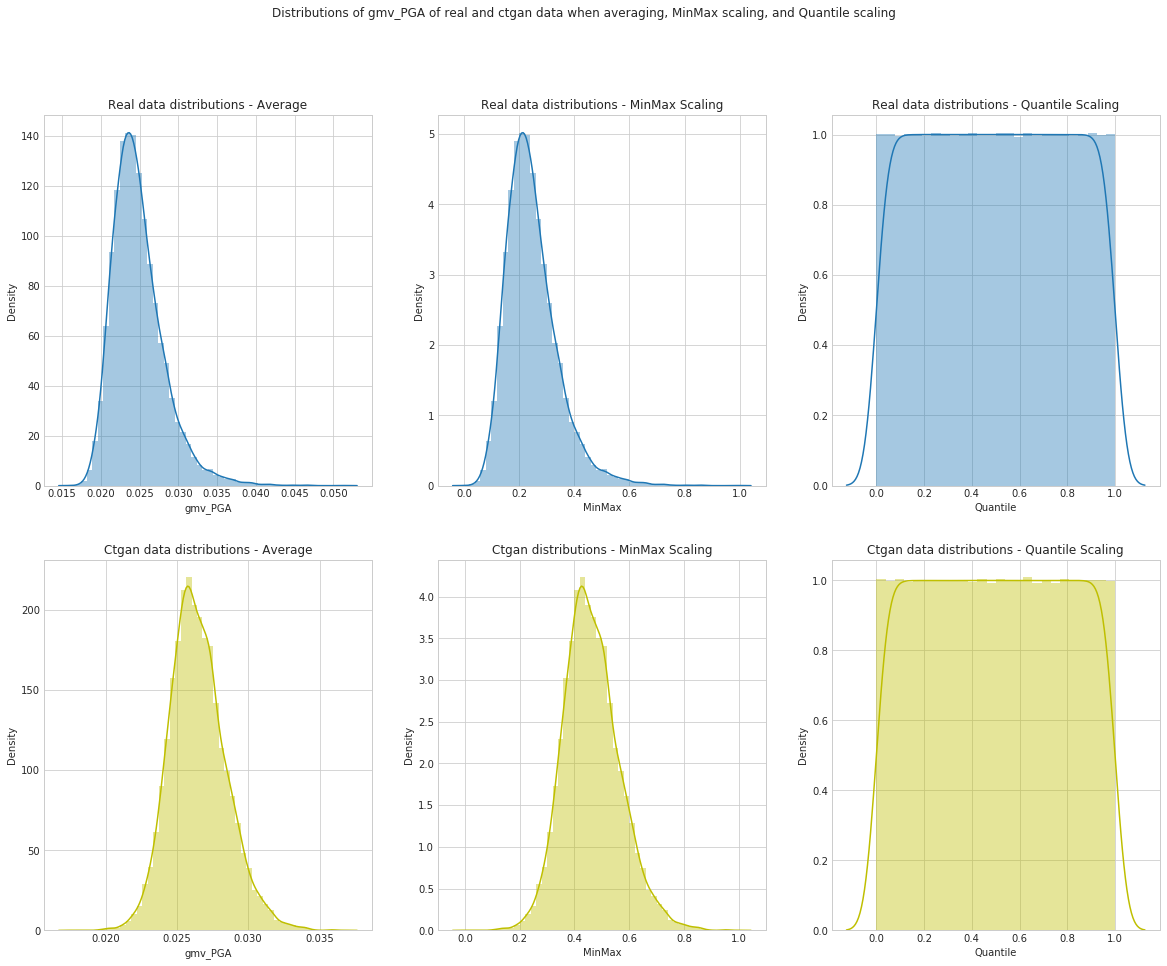

In [60]:
# Plotting the distributions of PGA
dis_plot('gmv_PGA')

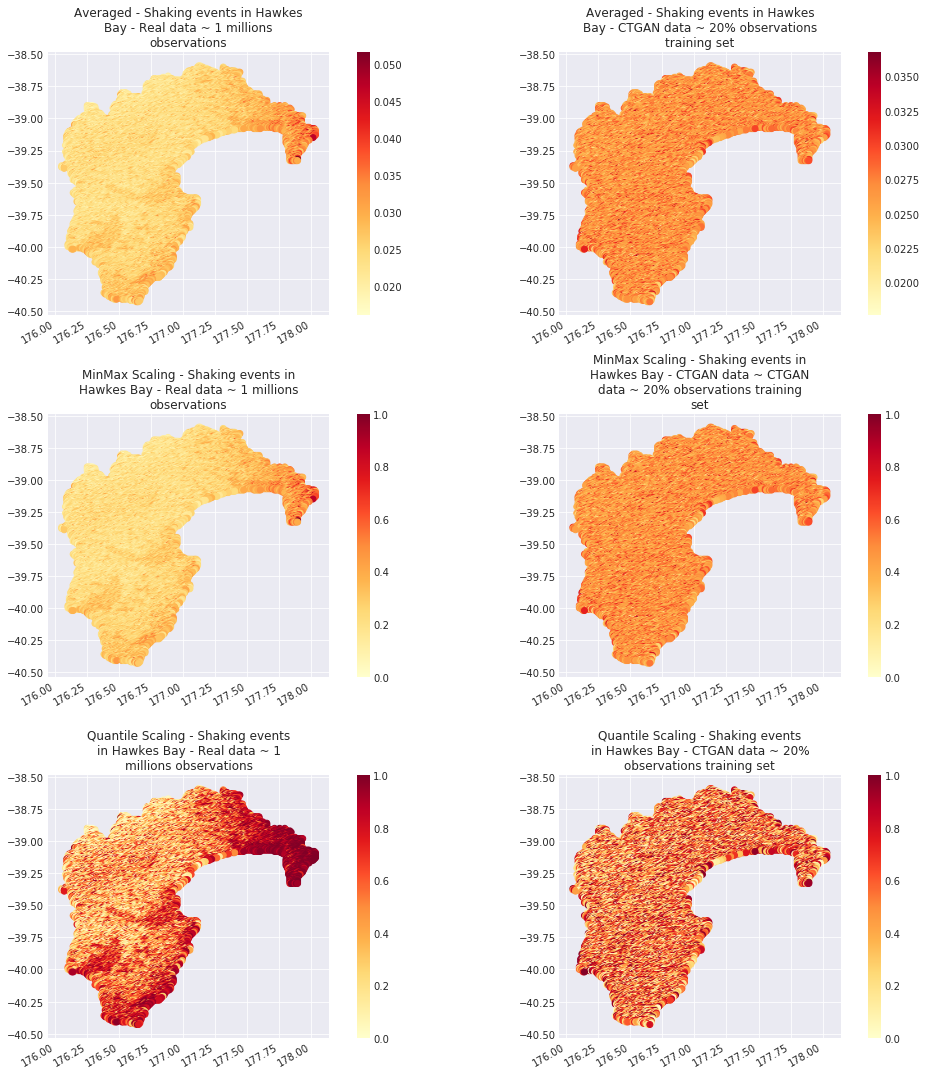

In [61]:
# Mapping the patterns of PGA
mapping('gmv_PGA')

<b>4.3.2. Mapping Vs30</b>

/data/tmn52/.local/lib/python3.7/site-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/opt/miniconda/lib/python3.7/site-packages/matplotlib/cbook/__init__.py:1402: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x[:, None]
/opt/miniconda/lib/python3.7/site-packages/matplotlib/axes/_base.py:276: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x = x[:, np.newaxis]
/opt/miniconda/lib/python3.7/site-packages/matplotlib/axes/_base.py:278: FutureWarning: Su

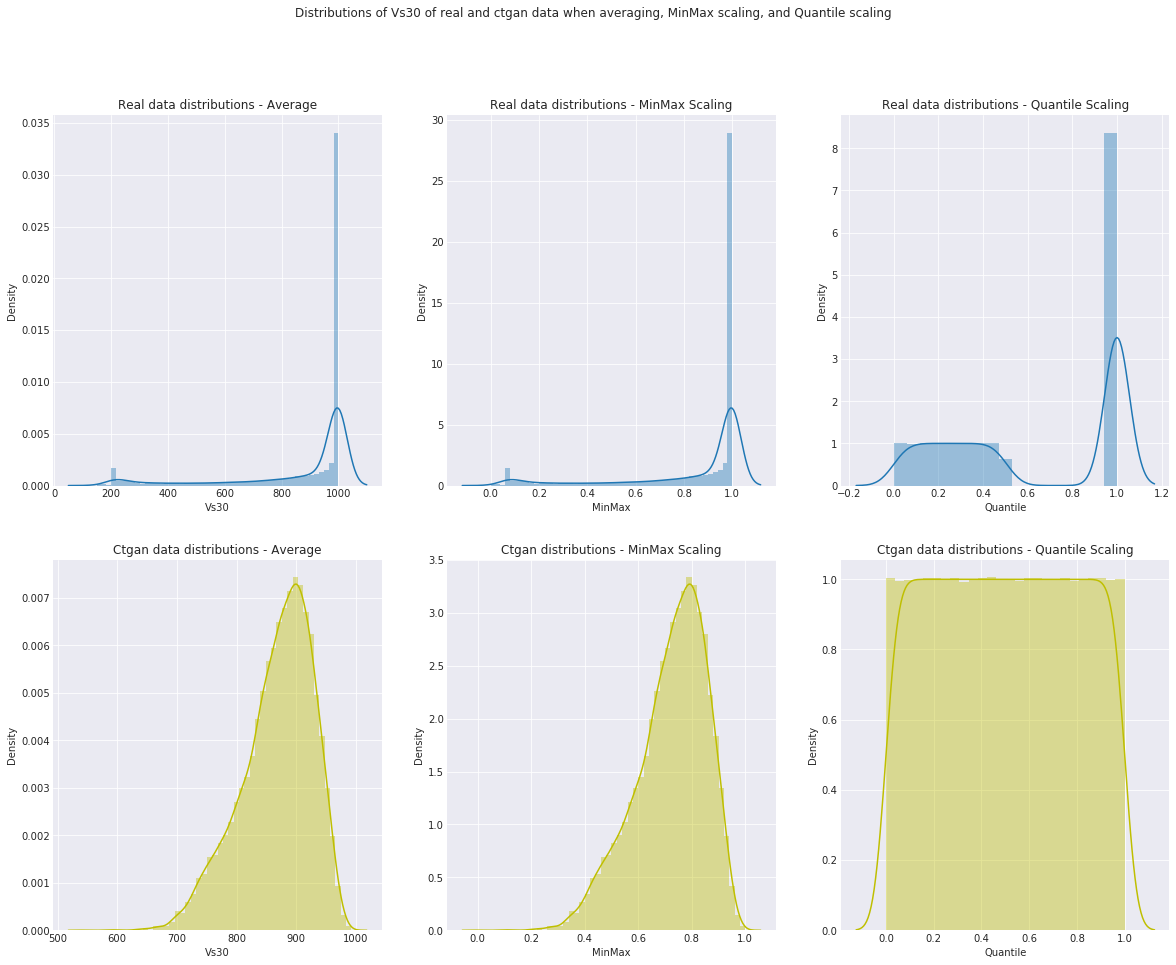

In [62]:
# Plotting the distributions of PGA
dis_plot('Vs30')

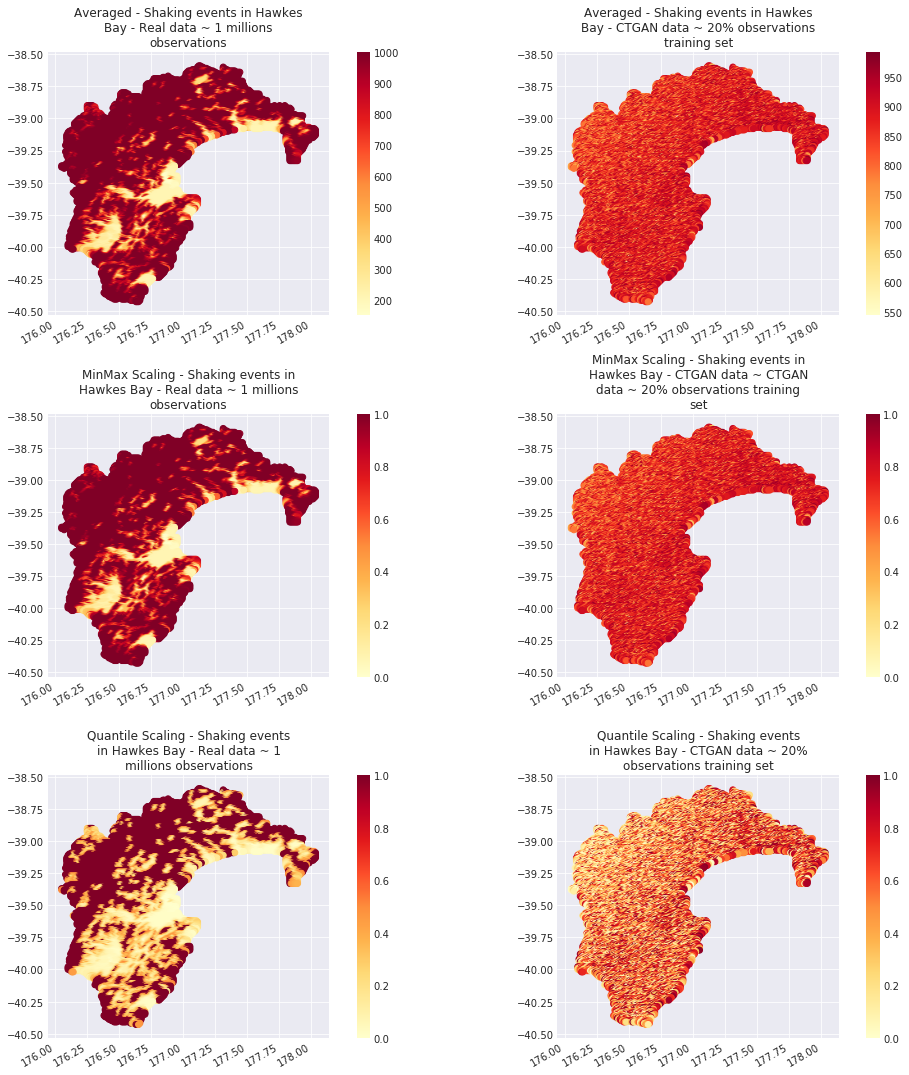

In [63]:
# Mapping the patterns of PGA
mapping('Vs30')

<b>4.3.3. Mapping Z2.5</b>

/data/tmn52/.local/lib/python3.7/site-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/opt/miniconda/lib/python3.7/site-packages/matplotlib/cbook/__init__.py:1402: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x[:, None]
/opt/miniconda/lib/python3.7/site-packages/matplotlib/axes/_base.py:276: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x = x[:, np.newaxis]
/opt/miniconda/lib/python3.7/site-packages/matplotlib/axes/_base.py:278: FutureWarning: Su

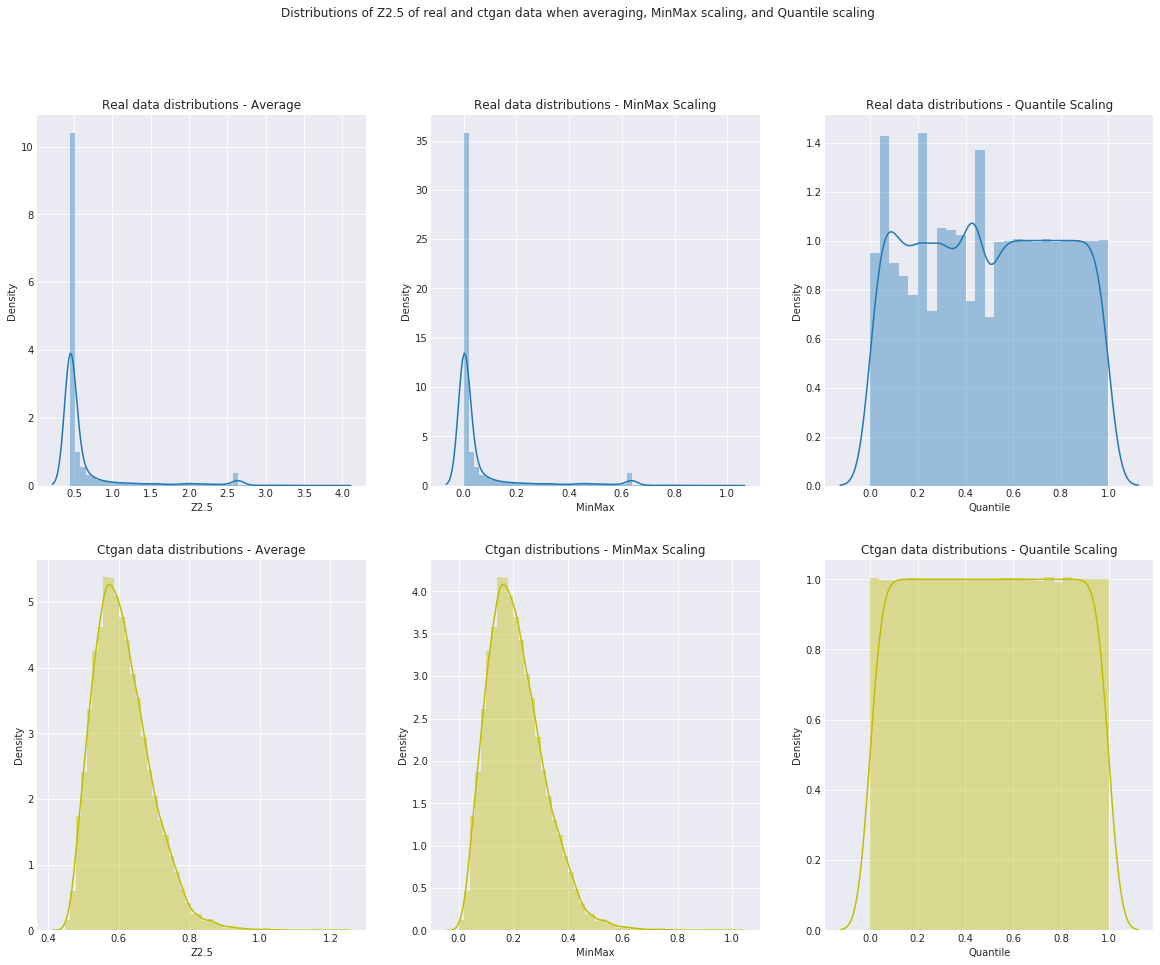

In [64]:
# Plotting the distributions of PGA
dis_plot('Z2.5')

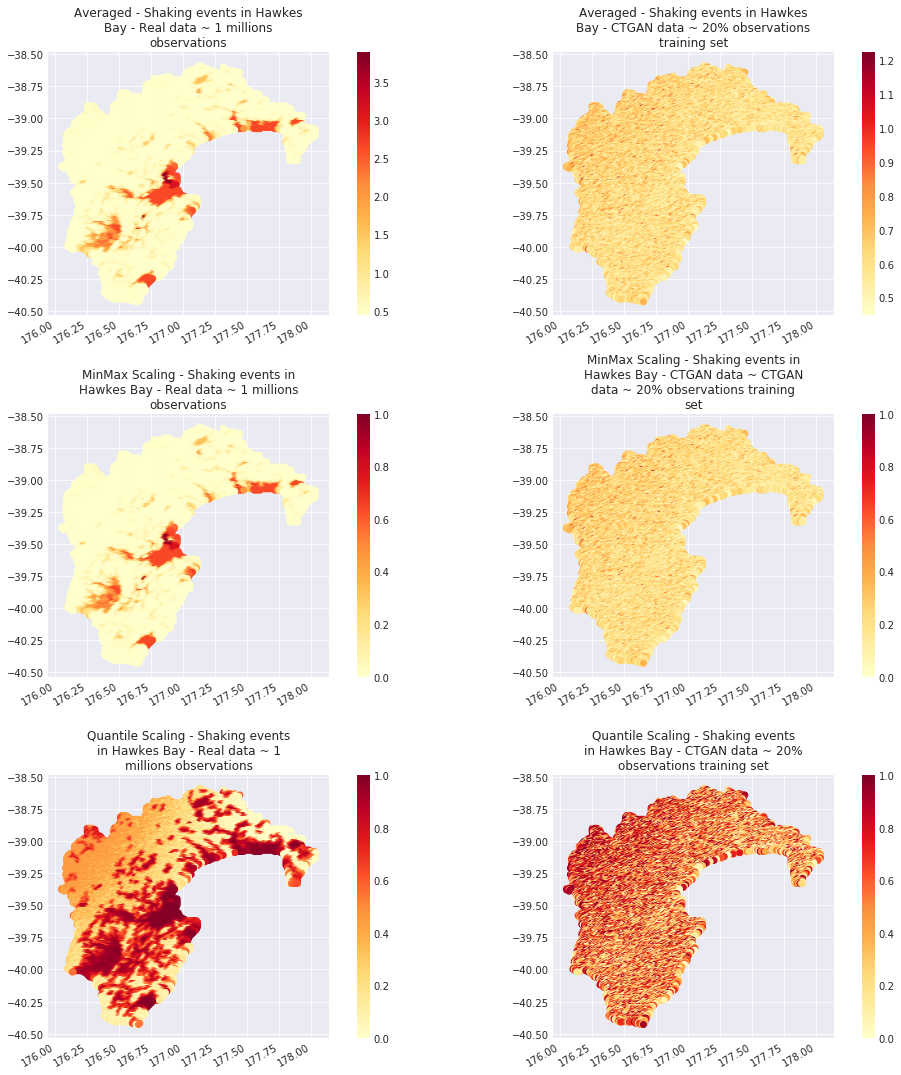

In [65]:
# Mapping the patterns of PGA
mapping('Z2.5')

<b>4.3.4. Mapping Z1.0</b>

/data/tmn52/.local/lib/python3.7/site-packages/seaborn/distributions.py:2557: FutureWarning: `distplot` is a deprecated function and will be removed in a future version. Please adapt your code to use either `displot` (a figure-level function with similar flexibility) or `histplot` (an axes-level function for histograms).
  warnings.warn(msg, FutureWarning)
/opt/miniconda/lib/python3.7/site-packages/matplotlib/cbook/__init__.py:1402: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x[:, None]
/opt/miniconda/lib/python3.7/site-packages/matplotlib/axes/_base.py:276: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  x = x[:, np.newaxis]
/opt/miniconda/lib/python3.7/site-packages/matplotlib/axes/_base.py:278: FutureWarning: Su

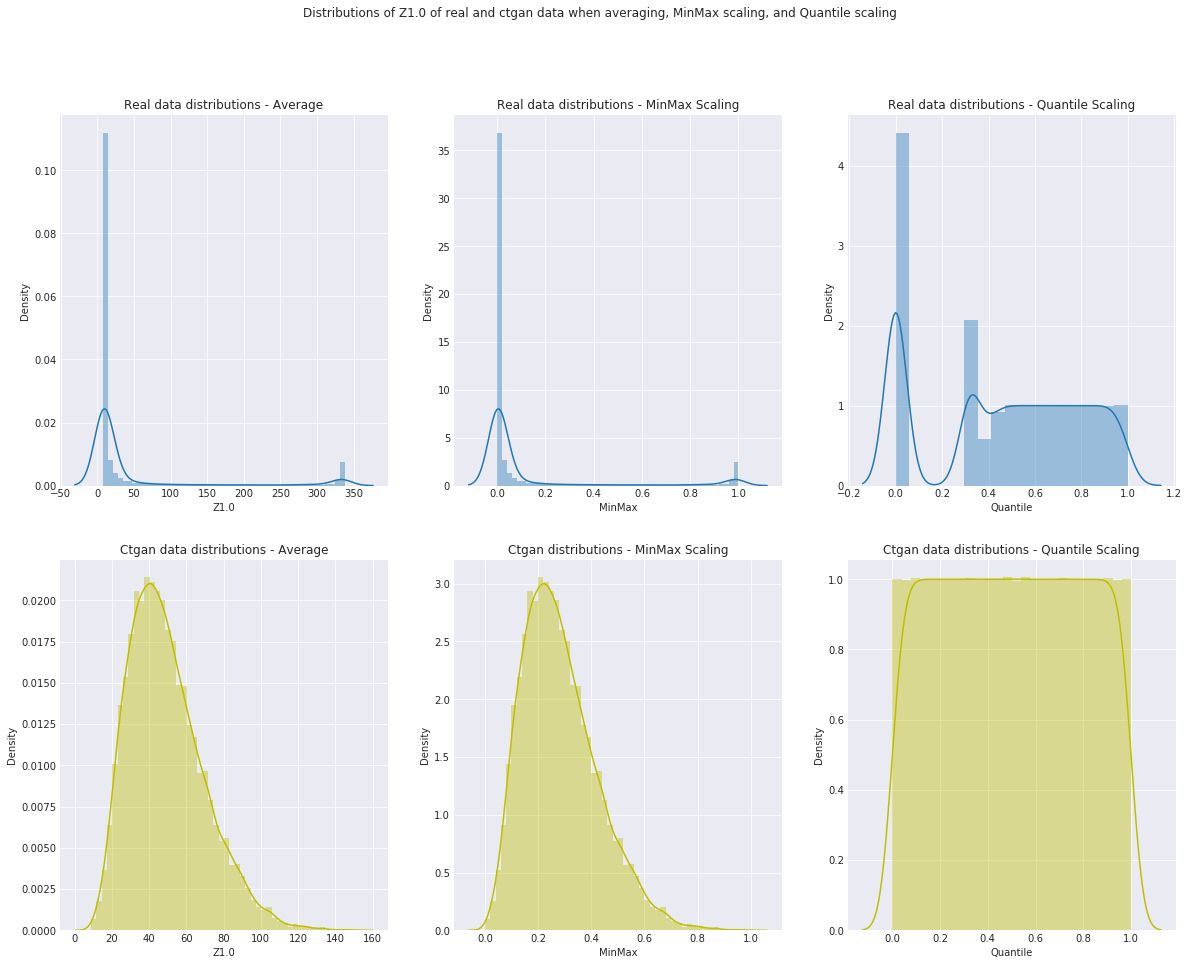

In [66]:
# Plotting the distributions of PGA
dis_plot('Z1.0')

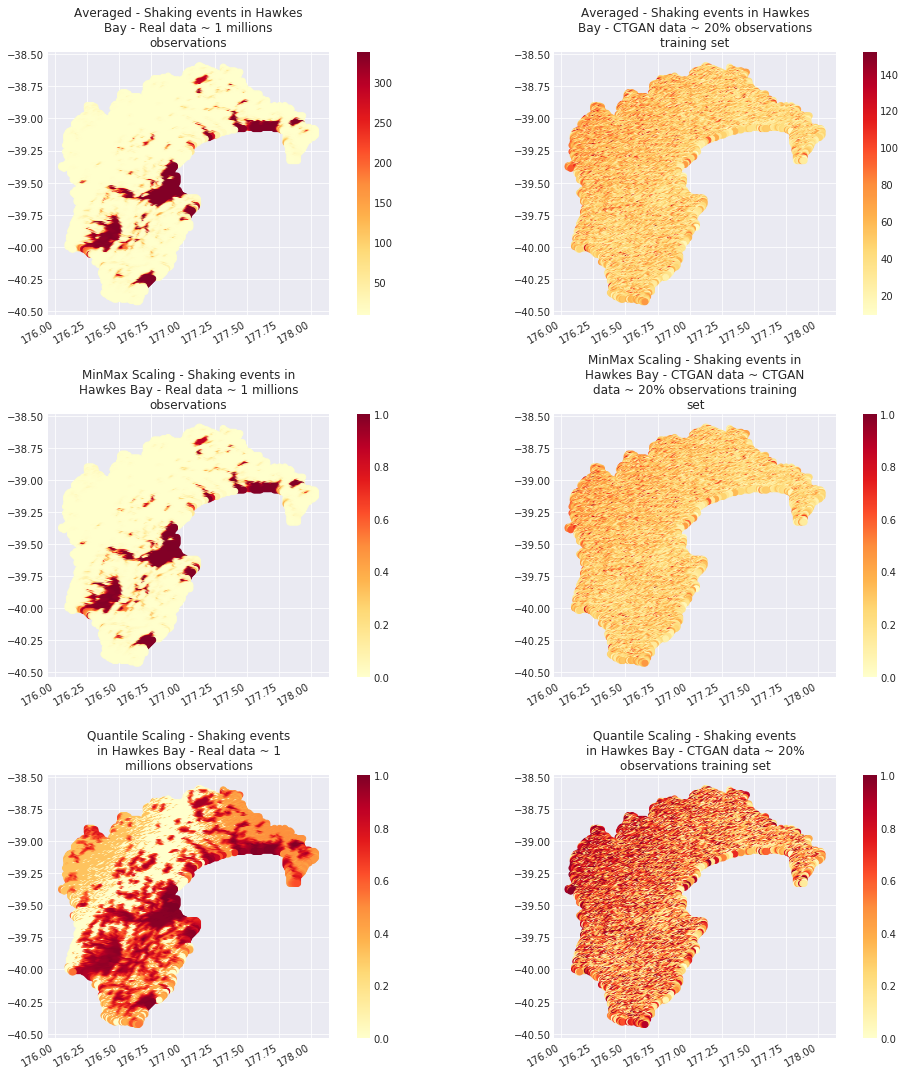

In [67]:
# Mapping the patterns of PGA
mapping('Z1.0')